# Backtesting Trading Strategies in Python
### Why backtests look better than reality — and how to build one that does not

*Based on L. H. Pedersen, **Efficiently Inefficient** (Princeton, 2015), Chapter 3: "Finding and Backtesting Strategies".*

A **backtest** simulates how a trading rule would have performed on historical data. It cannot tell you the strategy will work in the future, but it is very good at one thing: telling you that an idea *never* worked in the past — before you lose money on it. The danger is the opposite case: a backtest that looks wonderful. Pedersen's warning is that backtests *typically* look much better than the live performance that follows, and today's lesson is about the reasons why, with each reason reproduced in code.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

import warnings
warnings.filterwarnings('ignore')

def sharpe(returns, periods_per_year=252):
  "Annualised Sharpe ratio of a return series (risk-free rate = 0)."
  r = returns.dropna()
  return np.sqrt(periods_per_year) * r.mean() / r.std()

## 1. Where do trading profits come from?

Before testing a rule, ask **who is on the other side of the trade and why they would keep being there.** Repeatable sources of profit can be grouped into two families:

- **Compensation for information** — producing it (fundamental analysis), having faster access to it, or trading on public news that prices absorb slowly (post-earnings-announcement drift, momentum). The last one exists because arbitrage is limited: a cheap security can get cheaper first (noise-trader risk), the fund may face redemptions before the mispricing closes, and every "arbitrage" carries fundamental risk.
- **Compensation for liquidity risk** — holding assets that are costly to trade (*market* liquidity risk), costly to finance (*funding* liquidity risk), or taking the other side of *demand pressure* (index inclusions, forced sales after downgrades, hedgers in futures markets, merger-arbitrage).

Why this is of a first-order importance: a strategy with a *clear economic story* (a risk premium, a known behavioural pattern) deserves more trust from a given backtest than a pattern found by trying things.

**Discussion.** Which of these is a *repeatable* profit source? (a) you noticed gold rose in 7 of the last 10 Januaries; (b) you buy stocks that just got dropped from an index; (c) a friend made money shorting a stock last year; (d) you know next quarter's earnings before they are announced.

<details><summary>Explanation</summary>(b): providing liquidity to demand pressure, with an economic reason to expect it to recur. (a) is a pattern with no story and few observations; (c) is a backtest that is biased before you run it (you only heard about it because it worked); (d) is illegal.</details>

## 2. The four components of a backtest; two kinds of trading rules

Every backtest needs four things, and leaving any of them implicit is where errors hide:

| Component | Question | Today's example |
|---|---|---|
| **Universe** | Which securities could have been traded? | gold (one asset); later a simulated cross-section |
| **Signals** | What data, from where, and how is it transformed? | rolling highs/lows of the gold price |
| **Trading rule** | How often do you look, and how do you size positions? | enter/exit rule checked daily, fixed size |
| **Time lags** | Was the data really available when the rule used it? And could you trade at that price? | signal on today's close, trade at *tomorrow's* close |

For the **time lag** we have two separate issues: *availability* (GDP for a year is not known on 1 January; quarterly earnings arrive weeks after the quarter; both get revised later) and *executability* (a signal computed from today's close cannot be traded at today's close — academics often assume it can; a prudent backtest trades one or two days later).

We can distinguish two kinds of trading rules, and the code looks different for each:

- **Portfolio rebalance rule** — on each date, determine the target portfolio for the whole universe and rebalance to it. Example: every month-end, buy the cheapest 10% of stocks equally weighted. You always hold a portfolio; the question "did this trade work?" has no meaning.
- **Enter-exit rule** — for each asset separately: when to enter, how to size, how to resize, when to exit. Example: buy gold when its price exceeds its 20-day high, sell when it falls below its 10-day low. You may hold nothing for long stretches, and your risk changes as positions come and go.

We build the second one.

## 3. Worked example: a breakout rule on gold

**Rule.** Enter a long position in gold when today's close is above the highest close of the *previous* 20 trading days (a *breakout*). Exit when today's close is below the lowest close of the previous 10 trading days. No shorting. One unit of capital.

Note the word *previous*: the 20-day high must not include today, otherwise the price can never exceed it.

In [2]:
# download prices of gold
gold = yf.download('GLD', start='2005-01-01', end='2025-01-01',
                   interval='1d', progress=False, auto_adjust=True)['Close']
px = gold['GLD'].rename('price')
#compute log returns
ret = np.log(px).diff().rename('log_rtn')
print(f"{len(px)} trading days, {px.index[0].date()} to {px.index[-1].date()}")

5033 trading days, 2005-01-03 to 2024-12-31


In [3]:
# create the trading rule
def breakout_positions(price, entry_window=20, exit_window=10):
  "1 when long, 0 when flat. Signals use the PREVIOUS window (shift(1))."
  # compute the maximum over the entry window; note the shift
  prev_high = price.rolling(entry_window).max().shift(1)
  # compute the minimum over the exit window; note the shift
  prev_low  = price.rolling(exit_window).min().shift(1)
  # decision rule
  enter = price > prev_high
  leave = price < prev_low
  # create a trading state variable
  state = pd.Series(np.nan, index=price.index)
  state[enter] = 1.0            # entry signal
  state[leave] = 0.0            # exit signal
  return state.ffill().fillna(0.0)   # hold the last decision until a new signal

position = breakout_positions(px)
print(f"Share of days in the market: {position.mean():.0%}")
print(f"Number of entries: {int(((position == 1) & (position.shift(1) == 0)).sum())}")

Share of days in the market: 41%
Number of entries: 116


### 3.1 The execution lag

We know the position *decided* on day $t$. Which day's return does it earn? Three candidates:

- `lag = 0`: the position of day $t$ earns the return of day $t$. Impossible — the signal needs the close of $t$, which is also the price you would be "buying" at. This is **look-ahead bias**.
- `lag = 1`: decided at close $t$, executed at close $t+1$. The standard academic assumption.
- `lag = 2`: executed the day after. Lasse Heje Pedersen's "prudent" choice.

**Discussion.** How much of the strategy's return disappears from `lag = 0` to `lag = 1`? *(almost none / about half / most of it)*

In [4]:
# compute the strategy return for different time lags and compare
# create a dictionary
results = {}
for lag in [0, 1, 2]:
  strat = position.shift(lag) * ret
  results[f'lag {lag}'] = strat
# convert the dictionary into a DataFrame
results = pd.DataFrame(results).dropna()
results['buy & hold'] = ret.loc[results.index]

pd.DataFrame({'annual return': 252 * results.mean(),
              'annual vol': np.sqrt(252) * results.std(),
              'Sharpe': results.apply(sharpe)}).round(3)

,annual return,annual vol,Sharpe
lag 0,0.207,0.114,1.819
lag 1,0.030,0.114,0.263
lag 2,0.024,0.113,0.213
buy & hold,0.087,0.176,0.495


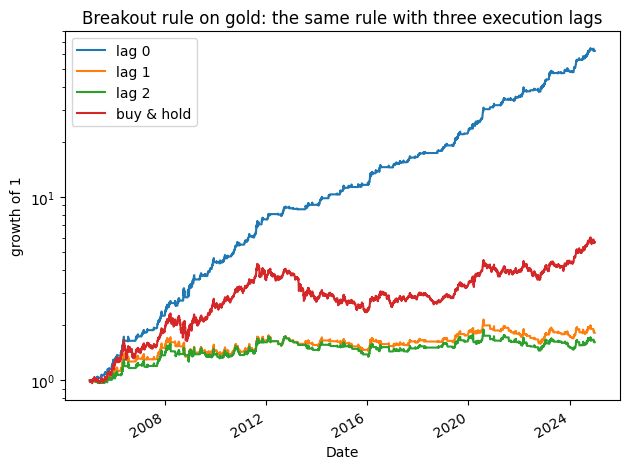

In [5]:
# create a figure of cumulative returns for each time lag
results.cumsum().apply(np.exp).plot(title='Breakout rule on gold: the same rule with three execution lags', logy=True)
plt.ylabel('growth of 1'); plt.tight_layout()

The `lag 0` line is the one an AI assistant (or a tired researcher) produces by default: `position * ret` without a shift. It is not a strategy; it is a description of the past. From here on, we use `lag = 1`, and you should treat `lag = 2` as the number you would quote to an investor.

 **Discussion.** `breakout_positions` already shifts the rolling high and low by one day. So why is `lag = 0` still look-ahead?

<details><summary>Explanation</summary>The shift inside the function stops *today's* price from being part of its own breakout threshold — it makes the signal well defined. The execution lag is a different thing: the signal uses the close of day $t$ and can only be traded <em>after</em> that close, so it must be paired with the return of $t+1$ or later. Two lags, two purposes.</details>

## 4. Data mining: the best backtest is not the best strategy

Pedersen claims is that **all** backtests suffer from data mining, and part of it is unavoidable: you looked at several versions of the idea and kept the one that worked; some version always works best by chance; and you only tested the idea because someone told you it made money. Two conclusions follow — discount backtest returns relative to live returns, and discount them *more* the more inputs the strategy has and the more it was tuned.

Let us make the unavoidable part visible. The breakout rule has two parameters (entry window, exit window). Nobody told us 20 and 10 are right. So we try a grid.

**Discussion.** We will try 10 $\times$ 10 = 100 parameter pairs on 2005-2014. How much higher will the best pair's Sharpe be than the (20, 10) default? *(roughly the same / +0.2 / +0.5 or more)*

In [6]:
entry_grid = [10, 20, 30, 40, 55, 70, 90, 120, 150, 200]
exit_grid  = [5, 10, 15, 20, 30, 40, 50, 70, 90, 120]
LAG = 1

in_sample  = slice('2005-01-01', '2014-12-31')
out_sample = slice('2015-01-01', '2024-12-31')

# compute the strategy returns within a function
def strategy_returns(entry_window, exit_window, lag=LAG):
  pos = breakout_positions(px, entry_window, exit_window)
  return (pos.shift(lag) * ret).dropna()

grid = pd.DataFrame(index=entry_grid, columns=exit_grid, dtype=float)
# compute in-sample Sharpe ratio for all the versions
for e in entry_grid:
  for x in exit_grid:
    grid.loc[e, x] = sharpe(strategy_returns(e, x).loc[in_sample])
grid.index.name = 'entry window'; grid.columns.name = 'exit window'
grid.round(2)

exit window,5,10,15,20,30,40,50,70,90,120
entry window,,,,,,,,,,
10,0.45,0.36,0.37,0.29,0.29,0.20,0.28,0.37,0.42,0.42
20,0.40,0.36,0.47,0.40,0.38,0.26,0.29,0.37,0.48,0.44
30,0.31,0.25,0.40,0.35,0.34,0.18,0.20,0.30,0.45,0.39
40,0.35,0.36,0.41,0.39,0.36,0.24,0.21,0.26,0.45,0.39
55,0.46,0.36,0.37,0.38,0.39,0.26,0.25,0.34,0.55,0.49
70,0.46,0.42,0.45,0.49,0.43,0.24,0.18,0.29,0.51,0.45
90,0.53,0.53,0.57,0.65,0.66,0.49,0.39,0.54,0.64,0.62
120,0.48,0.46,0.50,0.59,0.60,0.44,0.34,0.52,0.62,0.61
150,0.43,0.36,0.43,0.52,0.55,0.40,0.30,0.50,0.64,0.62


Default (20, 10): in-sample Sharpe 0.36
Best pair (90, 30): in-sample Sharpe 0.66


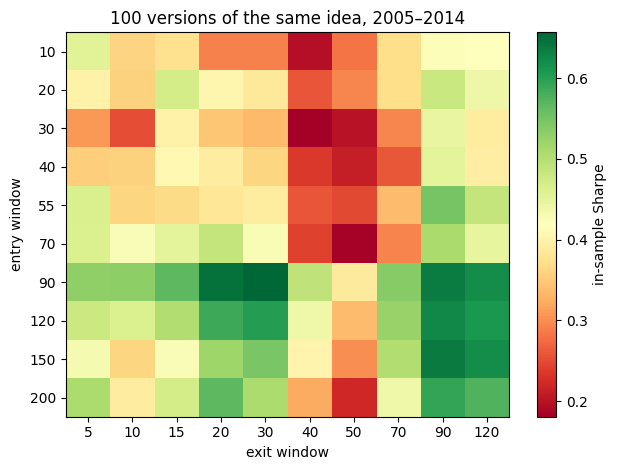

In [7]:
best = tuple(int(v) for v in grid.stack().idxmax())
print(f"Default (20, 10): in-sample Sharpe {grid.loc[20, 10]:.2f}")
print(f"Best pair {best}: in-sample Sharpe {grid.stack().max():.2f}")

plt.imshow(grid.values.astype(float), aspect='auto', cmap='RdYlGn')
plt.colorbar(label='in-sample Sharpe'); plt.xticks(range(len(exit_grid)), exit_grid); plt.yticks(range(len(entry_grid)), entry_grid)
plt.xlabel('exit window'); plt.ylabel('entry window'); plt.title('100 versions of the same idea, 2005–2014')
plt.tight_layout()

### 4.1 In-sample vs out-of-sample

The best pair was chosen *knowing* the whole of 2005-2014 — exactly what Pedersen calls an **in-sample test**: parameters estimated on the same data the strategy is then evaluated on. The honest question is how the pair chosen on 2005-2014 did on 2015-2024, which it never saw.

**Discussion.** Out of sample, is the optimised pair (a) still the best of the 100, (b) better than the default but not the best, (c) no better than the default?

Default (20, 10):  out-of-sample Sharpe 0.14  (rank 90 of 100)
In-sample best (90, 30): out-of-sample Sharpe 0.11  (rank 95 of 100)
Out-of-sample best: (10, 120) with Sharpe 0.61


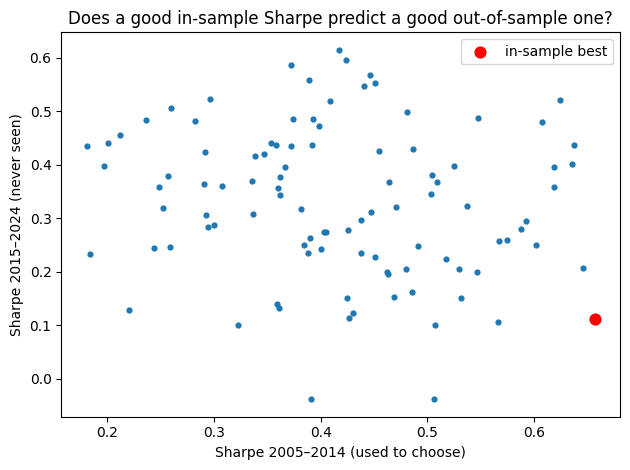

In [8]:
# out-of-sample
oos = pd.DataFrame(index=entry_grid, columns=exit_grid, dtype=float)
for e in entry_grid:
    for x in exit_grid:
        oos.loc[e, x] = sharpe(strategy_returns(e, x).loc[out_sample])

rank_oos = oos.stack().rank(ascending=False)
print(f"Default (20, 10):  out-of-sample Sharpe {oos.loc[20, 10]:.2f}  (rank {int(rank_oos.loc[(20, 10)])} of 100)")
print(f"In-sample best {best}: out-of-sample Sharpe {oos.loc[best]:.2f}  (rank {int(rank_oos.loc[best])} of 100)")
print(f"Out-of-sample best: {tuple(int(v) for v in oos.stack().idxmax())} with Sharpe {oos.stack().max():.2f}")

# create a scatter plot between in-sample and out-of-sample performance
plt.scatter(grid.stack(), oos.stack(), s=12)
plt.scatter(grid.loc[best], oos.loc[best], color='r', s=60, label='in-sample best')
plt.xlabel('Sharpe 2005–2014 (used to choose)'); plt.ylabel('Sharpe 2015–2024 (never seen)')
plt.legend(); plt.title('Does a good in-sample Sharpe predict a good out-of-sample one?')
plt.tight_layout()

Three ways to do an **out-of-sample test**, in increasing order of realism:

1. **Split sample** — choose parameters on the first half, evaluate on the second. What we just did.
2. **Rolling (walk-forward)** — each period, choose parameters on the data *before* it, trade the next period, repeat. The parameter choice is itself part of the strategy being tested.
3. **Don't have parameters** — the simplest strategies have little to tune and therefore little to overfit. Pedersen's advice: aim for a process that still works if you nudge it, not for the best backtest.

**Modify.** Flip the roles: choose the best pair on 2015-2024 and evaluate it on 2005-2014. Is the winner the same? What does it mean if it is not?

In [ ]:
# solution

## 5. Avoidable biases

Unlike data mining, these can be eliminated — and experienced researchers work hard to do so.

### 5.1 A biased universe (survivorship)

If you backtest on the stocks in an index *today*, you are using information from the future: you did not know fifteen years ago which companies would survive, grow and be included. The correct universe is the one that existed on each backtest date, delisted names included.

We cannot download historical index membership in class, so we **simulate** it, which has the advantage that we know the truth. 200 stocks, 15 years of monthly returns, identical expected returns by construction. A stock that loses 60% of its value is delisted (its investors keep what is left). Then we backtest the simplest possible strategy, buy-and-hold 1/N, on two universes: everything that ever existed, and only the names still alive at the end.


In [9]:
# create simulated stock returns
rng = np.random.default_rng(1234)
n_stocks, n_years = 200, 15
months = 12 * n_years
sigma = 0.30 / np.sqrt(12)                      # monthly vol: 30% a year
mu = np.log(1.06) / 12 - sigma**2 / 2           # log drift such that E[simple return] = 6% a year
# delist stock when their value fall below 40% of the starting value
DELIST_LEVEL = 0.40                             # delisted when value falls to 40% of start

r = rng.normal(mu, sigma, size=(months, n_stocks))

value = np.exp(np.cumsum(r, axis=0))             # value of 1 invested at t=0
# track delisting events
alive = np.ones_like(value, dtype=bool)
for j in range(n_stocks):
    hit = np.where(value[:, j] <= DELIST_LEVEL)[0]
    if len(hit):
        alive[hit[0]:, j] = False                # dead from the first breach onwards
        value[hit[0]:, j] = value[hit[0], j]     # liquidated: value frozen at delisting

survivors = alive[-1]
print(f"{survivors.sum()} of {n_stocks} stocks survive the 15 years")

full_universe = value.mean(axis=1)               # 1/N buy & hold, dead stocks keep their liquidation value
survivor_only = value[:, survivors].mean(axis=1)

for name, v in [('full universe (correct)', full_universe), ('survivors only (biased)', survivor_only)]:
    print(f"{name:26s} annualised return {v[-1]**(1/n_years) - 1:6.1%}")

125 of 200 stocks survive the 15 years
full universe (correct)    annualised return   5.6%
survivors only (biased)    annualised return   8.5%


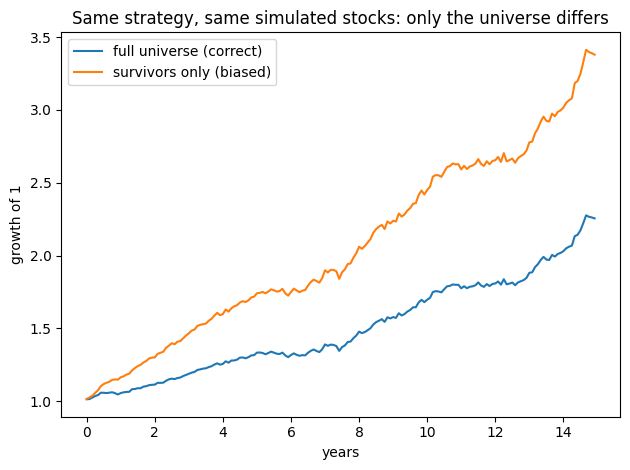

In [10]:
t = np.arange(months) / 12
plt.plot(t, full_universe, label='full universe (correct)')
plt.plot(t, survivor_only, label='survivors only (biased)')
plt.xlabel('years'); plt.ylabel('growth of 1'); plt.legend()
plt.title('Same strategy, same simulated stocks: only the universe differs')
plt.tight_layout()

The survivor-only backtest reports a return that no investor could have earned, from a strategy that contains no skill at all. Every exciting stock-picking backtest on "the S&P 500" or "the Nasdaq 100" built from today's constituent list has this problem.



## 6. Trading costs: the four-step adjustment

The recipe for a rebalance rule, each period: compute the portfolio return, compute the new positions and the implied trades, compute the expected cost of every trade and add them up, subtract from the return. The expected cost per trade comes from a broker or from a model; here we take a flat 10 basis points of traded value. The adjustment matters more the higher the **turnover**.

Applied to the breakout rule: a trade happens whenever the position changes, so the cost on day $t$ is $0.001 \times |\Delta \text{position}_t|$.

In [11]:
COST = 0.001                                    # 10 bp of traded value
pos = breakout_positions(px, 20, 10)
trades = pos.diff().abs()                       # 1 on days we enter or exit, else 0
gross = (pos.shift(1) * ret).dropna()
net = (gross - COST * trades.loc[gross.index]).dropna()

print(f"trades per year: {trades.sum() / (len(pos)/252):.1f}")
print(f"Sharpe gross {sharpe(gross):.2f}   net {sharpe(net):.2f}")
print(f"annual return gross {252*gross.mean():.2%}   net {252*net.mean():.2%}")

trades per year: 11.6
Sharpe gross 0.26   net 0.16
annual return gross 2.99%   net 1.83%


**Practice.** Set `entry_window=5, exit_window=3` — a fast version of the rule — and compare gross and net. Costs are a tax on turnover; the strategy that trades most pays most.

---
### Summary

- Know four components every backtest must state (universe, signals, rule, lags) and the two kinds of rule (rebalance vs enter-exit), and implement an enter-exit rule in `pandas`.
- Explain why `position * ret` without a shift is not a strategy, and why one extra day of lag is the number to quote.
- Show that a parameter grid produces a good backtest by itself, and test a choice out of sample (split or walk-forward).
- Build an unbiased universe, and recognise a timing signal that uses the future through its own sample mean.
- Adjust returns for trading costs and relate the hit to turnover.


---
## Practice exercises


**1. The classic rule.** The original "Turtle" rule used a 55-day entry and a 20-day exit. Backtest it on gold with `lag = 1` and `lag = 2`, with and without 10 bp costs. Report Sharpe and trades per year. Is it more or less robust to the lag than (20, 10), and why would you expect that?

In [ ]:
# solution

**2. Walk-forward parameter choice.** Implement Pedersen's rolling out-of-sample test: for each year from 2010 to 2024, choose the (entry, exit) pair with the best Sharpe over the *previous five years* from the grid in Section 4, and trade that pair during the year. Stitch the yearly returns together and compare the walk-forward Sharpe with (a) the fixed default (20, 10) and (b) the in-sample best from Section 4 evaluated on the same 2010-2024 window. Which of the three is the honest number?

In [ ]:
# solution

**3. How bad can survivorship get?** Rerun the simulation of 5.1 with `DELIST_LEVEL` equal to 0.2, 0.4, 0.6 and 0.8, and with volatility 15% and 45%. Tabulate the survivor-only annualised return against the true 6%. When is the bias largest, and what does that say about backtests on small-cap or growth-stock universes?

In [ ]:
# solution

<details><summary>Solutions</summary>

**1.**
```python
rows = []
for lag in [1, 2]:
    pos = breakout_positions(px, 55, 20)
    g = (pos.shift(lag) * ret).dropna()
    n = (g - COST * pos.diff().abs().loc[g.index])
    rows.append({'lag': lag, 'Sharpe gross': sharpe(g), 'Sharpe net': sharpe(n),
                 'trades/yr': pos.diff().abs().sum() / (len(pos)/252)})
print(pd.DataFrame(rows).round(2))
```
Slower rules trade less, so both the lag and the costs bite less — the signal is already "old" when it fires, and one more day changes little. Fast rules are the ones whose backtests collapse when you add a day.

**2.**
```python
pieces, chosen = [], {}
for year in range(2010, 2025):
    train = slice(f'{year-5}-01-01', f'{year-1}-12-31')
    best_pair, best_sr = None, -np.inf
    for e in entry_grid:
        for x in exit_grid:
            sr = sharpe(strategy_returns(e, x).loc[train])
            if sr > best_sr:
                best_pair, best_sr = (e, x), sr
    chosen[year] = best_pair
    pieces.append(strategy_returns(*best_pair).loc[f'{year}-01-01':f'{year}-12-31'])
walk_forward = pd.concat(pieces)
window = slice('2010-01-01', '2024-12-31')
print(f"walk-forward        {sharpe(walk_forward):.2f}")
print(f"fixed (20, 10)      {sharpe(strategy_returns(20, 10).loc[window]):.2f}")
print(f"in-sample best {best}  {sharpe(strategy_returns(*best).loc[window]):.2f}  (chosen using 2010-2014 data: partly in-sample)")
print(chosen)
```
The walk-forward number is the honest one: every parameter choice used only earlier data, and the *choosing* is part of what is tested. Notice how often the chosen pair changes — that instability is itself evidence that the parameters are mostly noise.

**3.**
```python
def survivorship_gap(delist_level, annual_vol, seed=2270):
    rng = np.random.default_rng(seed)
    sg = annual_vol/np.sqrt(12); r = rng.normal(np.log(1.06)/12 - sg**2/2, sg, size=(months, n_stocks))
    value = np.exp(np.cumsum(r, axis=0)); alive = np.ones_like(value, dtype=bool)
    for j in range(n_stocks):
        hit = np.where(value[:, j] <= delist_level)[0]
        if len(hit):
            alive[hit[0]:, j] = False; value[hit[0]:, j] = value[hit[0], j]
    surv = value[:, alive[-1]].mean(axis=1)
    return surv[-1]**(1/n_years) - 1, alive[-1].mean()

rows = [{'delist level': d, 'vol': v, 'survivor-only return': survivorship_gap(d, v)[0],
         'share surviving': survivorship_gap(d, v)[1]}
        for d in [0.2, 0.4, 0.6, 0.8] for v in [0.15, 0.30, 0.45]]
print(pd.DataFrame(rows).round(3))
```
The bias grows with volatility and with how easily a name drops out: exactly the universes (small caps, young growth firms, crypto tokens) where exciting backtests are most often reported.